# Notebook 01 – Khám phá và Tiền xử lý dữ liệu (EDA & Preprocessing)

**Nhóm thực hiện:** Nhóm 4 – Lớp: 68PM2 (HUCE – Mã HP: 608807)
**Thành viên:** Bình (Trưởng nhóm), Đức Anh (Phụ trách chính EDA & FE), Hà Duy, Hoàng, Trần Duy
**Đề tài 6 – Nhóm B:** Phát hiện giao dịch gian lận thẻ tín dụng (Credit Card Fraud Detection)
**Dữ liệu:** Kaggle *Credit Card Fraud Detection* (ULB Machine Learning Group), 284.807 giao dịch.
**Dạng bài toán:** Phân loại nhị phân cực kỳ mất cân bằng; chỉ số tối ưu là **PR-AUC** và **Recall**.

## Nội dung
1. Đọc dữ liệu và tổng quan
2. Chất lượng dữ liệu: giá trị thiếu, dòng trùng lặp, làm sạch
3. **Chia train/test (trước mọi bước học tham số từ dữ liệu)**
4. EDA trên tập train: phân phối lớp, `Amount`, `Time`, các biến `V1-V28`, tương quan
5. Xử lý ngoại lai (có thí nghiệm kiểm chứng)
6. Kỹ nghệ đặc trưng (Feature Engineering)
7. Thiết kế `ColumnTransformer` và kiểm chứng không rò rỉ dữ liệu
8. Mức độ quan trọng đặc trưng (phân tích đơn biến)
9. Tổng kết chiến lược tiền xử lý

## Nguyên tắc chống rò rỉ dữ liệu áp dụng trong notebook này
* Làm sạch dòng trùng và chia train/test được thực hiện **trước** mọi bước EDA sâu và mọi bước fit.
* Từ mục 4 trở đi, **mọi biểu đồ, thống kê, lựa chọn đặc trưng chỉ dùng tập train**. Tập test chưa được nhìn tới cho đến notebook 02, mục đánh giá cuối.
* Imputer, scaler, encoder chỉ `fit` trên train và chỉ `transform` trên test.

In [1]:
import sys
import warnings
from pathlib import Path

# Cho phép import module dùng chung (fraud_pipeline.py) nằm ở thư mục cha.
sys.path.insert(0, str(Path.cwd().parent))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats
from sklearn.feature_selection import f_classif
from sklearn.metrics import average_precision_score
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.base import BaseEstimator, TransformerMixin
from xgboost import XGBClassifier

from fraud_pipeline import (
    RANDOM_STATE, RAW_FEATURES, TARGET, TOP_V, V_COLUMNS,
    FraudFeatureEngineer, build_pipeline, build_preprocessor,
    clean_data, load_data, split_data,
)

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 100, "savefig.dpi": 150, "savefig.bbox": "tight"})
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
pd.set_option("display.max_columns", 50)

FIG_DIR = Path("../reports/figures")
TAB_DIR = Path("../reports/tables")
FIG_DIR.mkdir(parents=True, exist_ok=True)
TAB_DIR.mkdir(parents=True, exist_ok=True)
C_NORMAL, C_FRAUD = "#4C78A8", "#E45756"  # màu cố định: bình thường / gian lận


def save_fig(name: str) -> None:
    """Lưu hình hiện tại vào reports/figures để dùng cho báo cáo."""
    plt.savefig(FIG_DIR / f"{name}.png")


print("random_state =", RANDOM_STATE)

random_state = 42


## 1. Đọc dữ liệu và tổng quan

Bộ dữ liệu gồm các giao dịch thẻ tín dụng của khách hàng châu Âu trong **hai ngày** (tháng 9/2013).
* `Time`: số giây kể từ giao dịch đầu tiên trong bộ dữ liệu.
* `V1`-`V28`: các thành phần chính (PCA) của dữ liệu gốc. Tên và ý nghĩa gốc được ẩn vì lý do bảo mật, nên **không thể diễn giải nghiệp vụ** từng biến V.
* `Amount`: số tiền giao dịch.
* `Class` (biến mục tiêu): 1 = gian lận, 0 = bình thường.

In [2]:
df_raw = load_data()
print("Kích thước:", df_raw.shape)
df_raw.head()

Kích thước: (284807, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11,V12,V13,V14,V15,V16,V17,V18,V19,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0000,-1.3598,-0.0728,2.5363,1.3782,-0.3383,0.4624,0.2396,0.0987,0.3638,0.0908,-0.5516,-0.6178,-0.9914,-0.3112,1.4682,-0.4704,0.2080,0.0258,0.4040,0.2514,-0.0183,0.2778,-0.1105,0.0669,0.1285,-0.1891,0.1336,-0.0211,149.6200,0
1,0.0000,1.1919,0.2662,0.1665,0.4482,0.0600,-0.0824,-0.0788,0.0851,-0.2554,-0.1670,1.6127,1.0652,0.4891,-0.1438,0.6356,0.4639,-0.1148,-0.1834,-0.1458,-0.0691,-0.2258,-0.6387,0.1013,-0.3398,0.1672,0.1259,-0.0090,0.0147,2.6900,0
2,1.0000,-1.3584,-1.3402,1.7732,0.3798,-0.5032,1.8005,0.7915,0.2477,-1.5147,0.2076,0.6245,0.0661,0.7173,-0.1659,2.3459,-2.8901,1.1100,-0.1214,-2.2619,0.5250,0.2480,0.7717,0.9094,-0.6893,-0.3276,-0.1391,-0.0554,-0.0598,378.6600,0
3,1.0000,-0.9663,-0.1852,1.7930,-0.8633,-0.0103,1.2472,0.2376,0.3774,-1.3870,-0.0550,-0.2265,0.1782,0.5078,-0.2879,-0.6314,-1.0596,-0.6841,1.9658,-1.2326,-0.2080,-0.1083,0.0053,-0.1903,-1.1756,0.6474,-0.2219,0.0627,0.0615,123.5000,0
4,2.0000,-1.1582,0.8777,1.5487,0.4030,-0.4072,0.0959,0.5929,-0.2705,0.8177,0.7531,-0.8228,0.5382,1.3459,-1.1197,0.1751,-0.4514,-0.2370,-0.0382,0.8035,0.4085,-0.0094,0.7983,-0.1375,0.1413,-0.2060,0.5023,0.2194,0.2152,69.9900,0


In [3]:
df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     284807 non-nu

In [4]:
df_raw[["Time", "Amount", "V1", "V2", "V14", "Class"]].describe().T

,count,mean,std,min,25%,50%,75%,max
Time,"284,807.0000","94,813.8596","47,488.1460",0.0000,"54,201.5000","84,692.0000","139,320.5000","172,792.0000"
Amount,"284,807.0000",88.3496,250.1201,0.0000,5.6000,22.0000,77.1650,"25,691.1600"
V1,"284,807.0000",0.0000,1.9587,-56.4075,-0.9204,0.0181,1.3156,2.4549
V2,"284,807.0000",0.0000,1.6513,-72.7157,-0.5985,0.0655,0.8037,22.0577
V14,"284,807.0000",0.0000,0.9586,-19.2143,-0.4256,0.0506,0.4931,10.5268
Class,"284,807.0000",0.0017,0.0415,0.0000,0.0000,0.0000,0.0000,1.0000


## 2. Chất lượng dữ liệu và làm sạch

Kiểm tra giá trị thiếu, kiểu dữ liệu và dòng trùng lặp. Dòng trùng được **loại trước khi chia train/test**: nếu để lại, cùng một giao dịch có thể rơi vào cả hai tập và làm điểm test cao giả tạo (một dạng rò rỉ dữ liệu).

In [5]:
missing = df_raw.isna().sum()
print("Tổng số ô thiếu:", int(missing.sum()))
print("Kiểu dữ liệu:", df_raw.dtypes.value_counts().to_dict())

df_clean, clean_report = clean_data(df_raw)
report = pd.Series(clean_report, name="giá trị").to_frame()
report.index = [
    "Số dòng ban đầu", "Số dòng sau làm sạch", "Tổng ô thiếu",
    "Số dòng trùng đã loại", "Trong đó là giao dịch gian lận",
    "Số giao dịch gian lận còn lại", "Tỷ lệ gian lận sau làm sạch",
]
report.to_csv(TAB_DIR / "data_cleaning_report.csv")
report

Tổng số ô thiếu: 0
Kiểu dữ liệu: {dtype('float64'): 30, dtype('int64'): 1}


,giá trị
Số dòng ban đầu,"284,807.0000"
Số dòng sau làm sạch,"283,726.0000"
Tổng ô thiếu,0.0000
Số dòng trùng đã loại,"1,081.0000"
Trong đó là giao dịch gian lận,19.0000
Số giao dịch gian lận còn lại,473.0000
Tỷ lệ gian lận sau làm sạch,0.0017


In [6]:
# Ví dụ vài dòng trùng lặp hoàn toàn (hiển thị một số cột)
dup_mask = df_raw.duplicated(keep=False)
df_raw[dup_mask].sort_values(["Time", "Amount"]).head(6)[["Time", "V1", "V2", "Amount", "Class"]]

,Time,V1,V2,Amount,Class
34,26.0000,-0.5354,0.8653,1.7700,0
35,26.0000,-0.5354,0.8653,1.7700,0
32,26.0000,-0.5299,0.8739,6.1400,0
33,26.0000,-0.5299,0.8739,6.1400,0
112,74.0000,1.0384,0.1275,1.1800,0
113,74.0000,1.0384,0.1275,1.1800,0


**Nhận xét.**
* Bộ dữ liệu **không có giá trị thiếu** và toàn bộ cột là số, nên không cần mã hóa nhãn. Tuy vậy `SimpleImputer` vẫn được đặt trong Pipeline để pipeline vẫn chạy được khi gặp dữ liệu thực tế có thiếu sót.
* Có **1.081 dòng trùng lặp** (19 dòng là gian lận). Sau khi loại còn **283.726 giao dịch**, trong đó **473 gian lận (0,1667%)**.

## 3. Chia train/test

Chia **80/20, phân tầng (stratified) theo `Class`** ngay sau bước làm sạch. Tập test được cất riêng, chỉ dùng **một lần duy nhất** ở cuối notebook 02 để đánh giá khách quan.

Vì chỉ có 473 giao dịch gian lận, tập test chứa chưa đến 100 ca gian lận, nên các chỉ số trên test dao động khá mạnh. Notebook 02 sẽ cung cấp khoảng tin cậy bootstrap để phản ánh điều đó.

In [7]:
X_train, X_test, y_train, y_test = split_data(df_clean)

split_summary = pd.DataFrame({
    "Số giao dịch": [len(X_train), len(X_test)],
    "Số gian lận": [int(y_train.sum()), int(y_test.sum())],
    "Tỷ lệ gian lận (%)": [100 * y_train.mean(), 100 * y_test.mean()],
}, index=["Train (80%)", "Test (20%)"])
split_summary.to_csv(TAB_DIR / "split_summary.csv")
split_summary

,Số giao dịch,Số gian lận,Tỷ lệ gian lận (%)
Train (80%),226980,378,0.1665
Test (20%),56746,95,0.1674


In [8]:
# Từ đây trở đi EDA chỉ dùng tập TRAIN.
train = X_train.assign(Class=y_train)
fraud, normal = train[train.Class == 1], train[train.Class == 0]
print(f"Train: {len(train):,} dòng | gian lận: {len(fraud)} | bình thường: {len(normal):,}")

Train: 226,980 dòng | gian lận: 378 | bình thường: 226,602


## 4. Khám phá dữ liệu (EDA) trên tập train

### 4.1 Phân phối biến mục tiêu

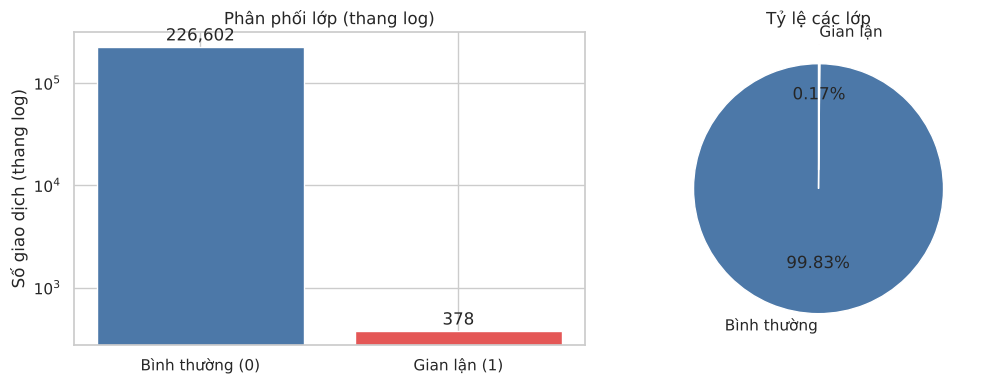

Chỉ cần dự đoán 'bình thường' cho mọi giao dịch đã đạt Accuracy = 99.8335% nhưng bỏ sót 100% gian lận. Vì vậy Accuracy không dùng được; tối ưu PR-AUC và Recall.


In [9]:
counts = train.Class.value_counts().sort_index()
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].bar(["Bình thường (0)", "Gian lận (1)"], counts.values, color=[C_NORMAL, C_FRAUD])
axes[0].set_yscale("log")
axes[0].set_ylabel("Số giao dịch (thang log)")
axes[0].set_title("Phân phối lớp (thang log)")
for i, v in enumerate(counts.values):
    axes[0].text(i, v * 1.15, f"{v:,}", ha="center")
axes[1].pie(counts.values, labels=["Bình thường", "Gian lận"], colors=[C_NORMAL, C_FRAUD],
            autopct="%.2f%%", startangle=90, explode=(0, 0.15))
axes[1].set_title("Tỷ lệ các lớp")
plt.tight_layout()
save_fig("01_class_distribution")
plt.show()

accuracy_dummy = counts.max() / counts.sum()
print(f"Chỉ cần dự đoán 'bình thường' cho mọi giao dịch đã đạt Accuracy = {accuracy_dummy:.4%} "
      "nhưng bỏ sót 100% gian lận. Vì vậy Accuracy không dùng được; tối ưu PR-AUC và Recall.")

**Nhận xét.** Tỷ lệ gian lận chỉ khoảng 0,17%, tức khoảng 1 gian lận trên 600 giao dịch. Mất cân bằng cực đoan này kéo theo ba quyết định cho các bước sau:
1. Dùng **PR-AUC** (Average Precision) làm chỉ số chính vì nó chỉ tập trung vào lớp hiếm, không bị lớp đa số làm phồng như ROC-AUC. Theo dõi thêm **Recall**, F2, MCC.
2. Dùng **StratifiedKFold** để mỗi fold đều có đủ giao dịch gian lận.
3. Thử các chiến lược xử lý mất cân bằng (trọng số lớp, SMOTE, undersampling) **bên trong Pipeline**.

### 4.2 Số tiền giao dịch (`Amount`)

In [10]:
amount_stats = train.groupby("Class").Amount.describe(percentiles=[.25, .5, .75, .95, .99])
amount_stats.index = ["Bình thường", "Gian lận"]
amount_stats.to_csv(TAB_DIR / "amount_stats_by_class.csv")
display(amount_stats)

u, p = stats.mannwhitneyu(fraud.Amount, normal.Amount)
print(f"Mann-Whitney U (Amount giữa 2 lớp): p-value = {p:.3g}")
print(f"Tỷ lệ giao dịch có Amount < 1: gian lận {(fraud.Amount < 1).mean():.1%} "
      f"vs bình thường {(normal.Amount < 1).mean():.1%}")
print(f"Tỷ lệ giao dịch có Amount = 0: gian lận {(fraud.Amount == 0).mean():.1%} "
      f"vs bình thường {(normal.Amount == 0).mean():.1%}")

,count,mean,std,min,25%,50%,75%,95%,99%,max
Bình thường,"226,602.0000",88.3412,245.7654,0.0000,5.7400,22.0800,77.7100,364.2500,"1,015.6991","19,656.5300"
Gian lận,378.0000,115.9394,245.5527,0.0000,1.0000,9.5550,104.6150,574.6930,"1,347.5488","2,125.8700"


Mann-Whitney U (Amount giữa 2 lớp): p-value = 0.000106
Tỷ lệ giao dịch có Amount < 1: gian lận 12.7% vs bình thường 5.9%
Tỷ lệ giao dịch có Amount = 0: gian lận 4.8% vs bình thường 0.6%


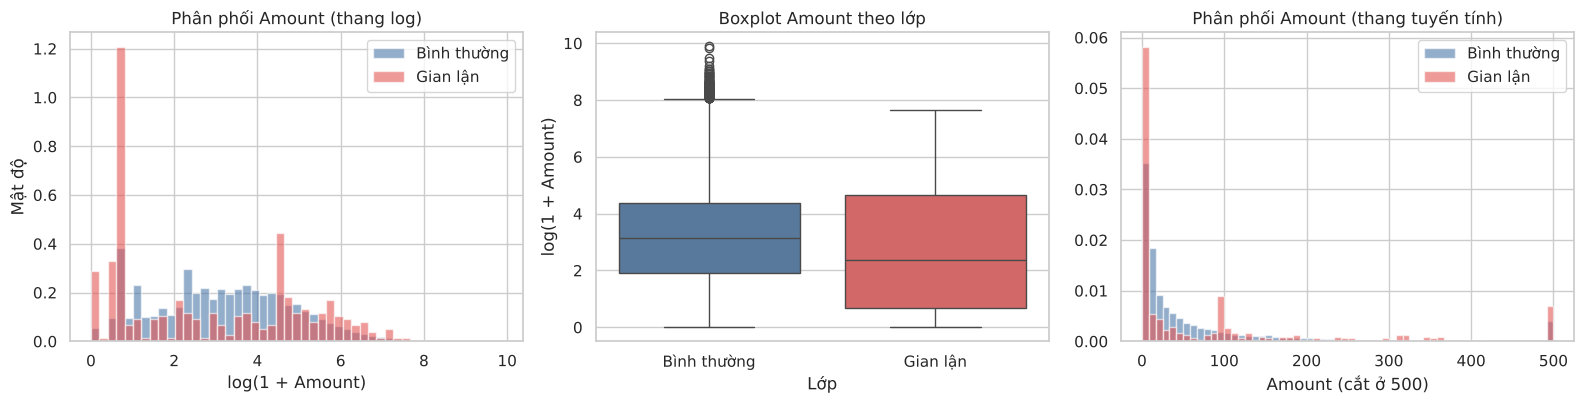

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
bins = np.linspace(0, np.log1p(train.Amount.max()), 50)
for data, name, c in [(normal, "Bình thường", C_NORMAL), (fraud, "Gian lận", C_FRAUD)]:
    axes[0].hist(np.log1p(data.Amount), bins=bins, density=True, alpha=0.6, label=name, color=c)
axes[0].set(xlabel="log(1 + Amount)", ylabel="Mật độ", title="Phân phối Amount (thang log)")
axes[0].legend()

sns.boxplot(data=train.assign(logAmount=np.log1p(train.Amount),
                              Lớp=train.Class.map({0: "Bình thường", 1: "Gian lận"})),
            x="Lớp", y="logAmount", hue="Lớp", palette=[C_NORMAL, C_FRAUD],
            legend=False, ax=axes[1])
axes[1].set(ylabel="log(1 + Amount)", title="Boxplot Amount theo lớp")

axes[2].hist(normal.Amount.clip(upper=500), bins=60, density=True, alpha=0.6, color=C_NORMAL, label="Bình thường")
axes[2].hist(fraud.Amount.clip(upper=500), bins=60, density=True, alpha=0.6, color=C_FRAUD, label="Gian lận")
axes[2].set(xlabel="Amount (cắt ở 500)", title="Phân phối Amount (thang tuyến tính)")
axes[2].legend()
plt.tight_layout()
save_fig("02_amount_distribution")
plt.show()

**Nhận xét.** `Amount` lệch phải rất mạnh (đuôi dài tới hàng chục nghìn), nên chuẩn hóa bằng `StandardScaler` sẽ bị đuôi này chi phối. Giao dịch gian lận có trung vị thấp hơn nhưng tỷ lệ giao dịch số tiền rất nhỏ (< 1) cao gấp khoảng hai lần giao dịch bình thường, phù hợp với kiểu tin tặc "dò thẻ" bằng các khoản nhỏ trước khi rút khoản lớn. Hai quyết định rút ra:
* dùng `log1p(Amount)` và `RobustScaler` cho nhóm số tiền;
* thêm cờ nhị phân `Amount_small` (Amount < 1).

### 4.3 Thời gian giao dịch (`Time`)
`Time` là số giây kể từ giao dịch đầu tiên của bộ dữ liệu. Nhóm quy đổi thành "giờ trong ngày" bằng `(Time mod 86400) / 3600`. Đây là giờ **tương đối** so với giao dịch đầu tiên (nguồn dữ liệu không nói rõ mốc 0 giờ), nhưng với hai ngày dữ liệu thì chu kỳ ngày vẫn thể hiện được.

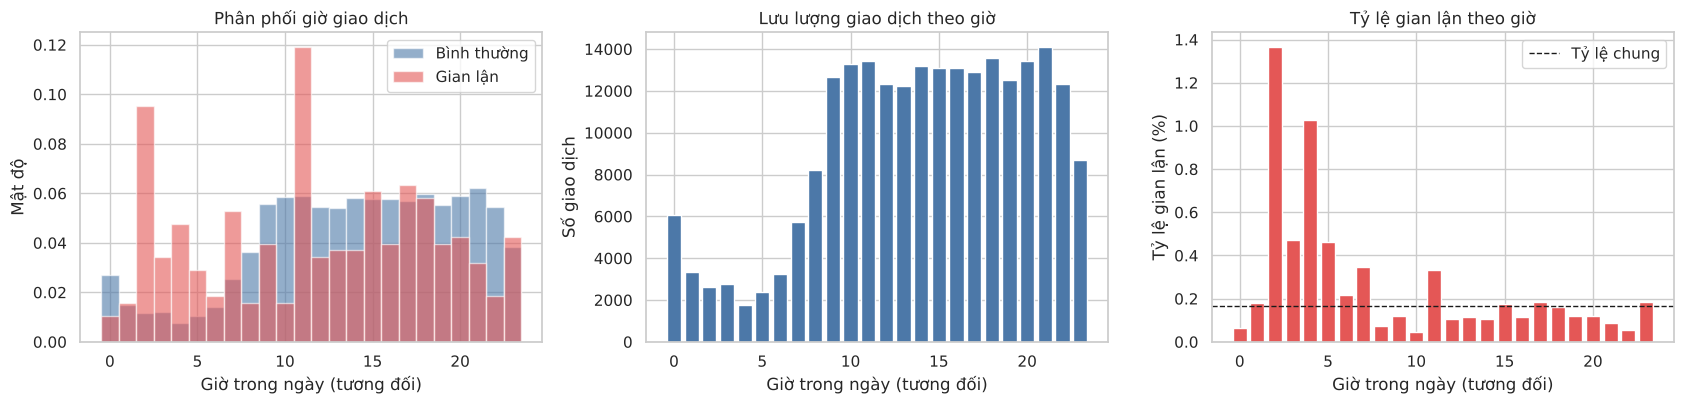

,Bình thường,Gian lận,Tỷ lệ gian lận (%)
Time,,,
night (0-6h),18863,88,0.4644
morning (6-12h),56486,99,0.1750
afternoon (12-18h),76731,103,0.1341
evening (18-24h),74522,88,0.1179


Kiểm định chi-bình phương (khung giờ vs nhãn): p-value = 3.75e-25


In [12]:
train_t = train.assign(Hour=((train.Time % 86400) // 3600).astype(int))
hourly = train_t.groupby("Hour").Class.agg(["sum", "count"])
hourly["rate_pct"] = 100 * hourly["sum"] / hourly["count"]

fig, axes = plt.subplots(1, 3, figsize=(17, 4.2))
for data, name, c in [(train_t[train_t.Class == 0], "Bình thường", C_NORMAL),
                      (train_t[train_t.Class == 1], "Gian lận", C_FRAUD)]:
    axes[0].hist(data.Hour, bins=np.arange(25) - 0.5, density=True, alpha=0.6, label=name, color=c)
axes[0].set(xlabel="Giờ trong ngày (tương đối)", ylabel="Mật độ", title="Phân phối giờ giao dịch")
axes[0].legend()

axes[1].bar(hourly.index, hourly["count"], color=C_NORMAL)
axes[1].set(xlabel="Giờ trong ngày (tương đối)", ylabel="Số giao dịch", title="Lưu lượng giao dịch theo giờ")

axes[2].bar(hourly.index, hourly.rate_pct, color=C_FRAUD)
axes[2].axhline(100 * train.Class.mean(), color="k", ls="--", lw=1, label="Tỷ lệ chung")
axes[2].set(xlabel="Giờ trong ngày (tương đối)", ylabel="Tỷ lệ gian lận (%)", title="Tỷ lệ gian lận theo giờ")
axes[2].legend()
plt.tight_layout()
save_fig("03_time_distribution")
plt.show()

# Kiểm định khi-bình phương giữa khung giờ và nhãn
period = pd.cut((train.Time % 86400) / 3600, bins=[-0.001, 6, 12, 18, 24.001],
                labels=["night (0-6h)", "morning (6-12h)", "afternoon (12-18h)", "evening (18-24h)"])
ct = pd.crosstab(period, train.Class)
chi2, p_chi, _, _ = stats.chi2_contingency(ct)
tab = ct.assign(rate_pct=100 * ct[1] / ct.sum(axis=1))
tab.columns = ["Bình thường", "Gian lận", "Tỷ lệ gian lận (%)"]
tab.to_csv(TAB_DIR / "fraud_rate_by_period.csv")
display(tab)
print(f"Kiểm định chi-bình phương (khung giờ vs nhãn): p-value = {p_chi:.3g}")

**Nhận xét.** Lưu lượng giao dịch có chu kỳ ngày rõ rệt (thấp ở các giờ đêm), trong khi tỷ lệ gian lận lại **cao nhất ở khung giờ đêm** (khoảng 0,46%, cao gấp gần 3 lần mức chung 0,17%). Một cách giải thích khả dĩ là giao dịch hợp lệ giảm mạnh vào ban đêm trong khi gian lận không giảm theo, nhưng dữ liệu ẩn danh nên đây chỉ là giả thuyết. Kiểm định khi-bình phương cho p-value rất nhỏ, tức khung giờ có liên hệ với nhãn. Điều này biện minh cho:
* đặc trưng chu kỳ `Hour_sin`, `Hour_cos` (giờ 23h và 0h gần nhau);
* biến phân loại `Period` (khung giờ) để thực hành mã hóa `OneHotEncoder`;
* loại bỏ `Time` thô (giá trị tuyệt đối chỉ phản ánh vị trí trong 2 ngày thu thập, không tổng quát hóa).

### 4.4 Các biến ẩn danh `V1`-`V28`
Dùng thống kê Kolmogorov-Smirnov (KS) giữa hai lớp để xếp hạng khả năng phân tách từng biến, sau đó xem phân phối của các biến mạnh nhất.

,Biến,KS,p_value,Chênh lệch trung bình
0,V14,0.8500,0.0000,-7.0597
1,V10,0.8159,0.0000,-5.5705
2,V12,0.7865,0.0000,-6.1984
3,V4,0.7581,0.0000,4.5079
4,V17,0.7515,0.0000,-6.6306
5,V11,0.7470,0.0000,3.8002
6,V3,0.7125,0.0000,-6.9817
7,V16,0.6834,0.0000,-4.0780
8,V7,0.6664,0.0000,-5.3271
9,V2,0.6392,0.0000,3.5393


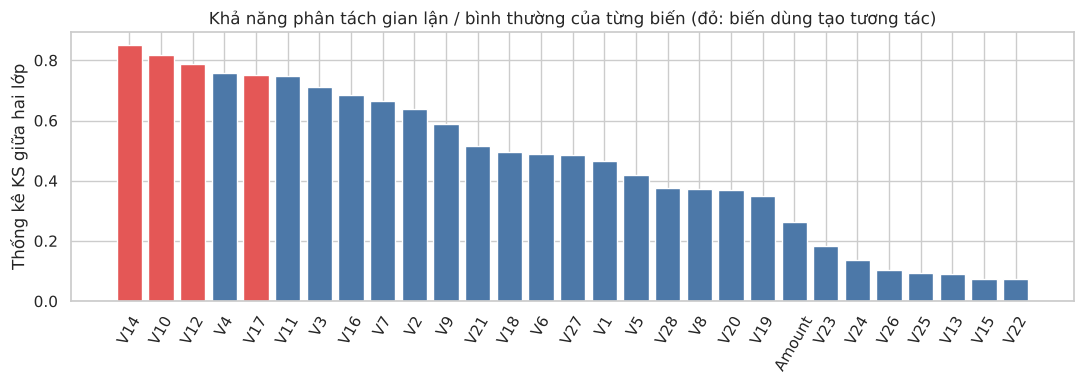

In [13]:
ks_rows = []
for col in V_COLUMNS + ["Amount"]:
    ks, p = stats.ks_2samp(fraud[col], normal[col])
    ks_rows.append((col, ks, p, fraud[col].mean() - normal[col].mean()))
ks_df = (pd.DataFrame(ks_rows, columns=["Biến", "KS", "p_value", "Chênh lệch trung bình"])
         .sort_values("KS", ascending=False).reset_index(drop=True))
ks_df.to_csv(TAB_DIR / "ks_ranking.csv", index=False)
display(ks_df.head(10))

fig, ax = plt.subplots(figsize=(11, 4))
ordered = ks_df.sort_values("KS", ascending=False)
ax.bar(ordered["Biến"], ordered["KS"], color=[C_FRAUD if v in TOP_V else C_NORMAL for v in ordered["Biến"]])
ax.set(ylabel="Thống kê KS giữa hai lớp", title="Khả năng phân tách gian lận / bình thường của từng biến (đỏ: biến dùng tạo tương tác)")
plt.xticks(rotation=60)
plt.tight_layout()
save_fig("04_ks_ranking")
plt.show()

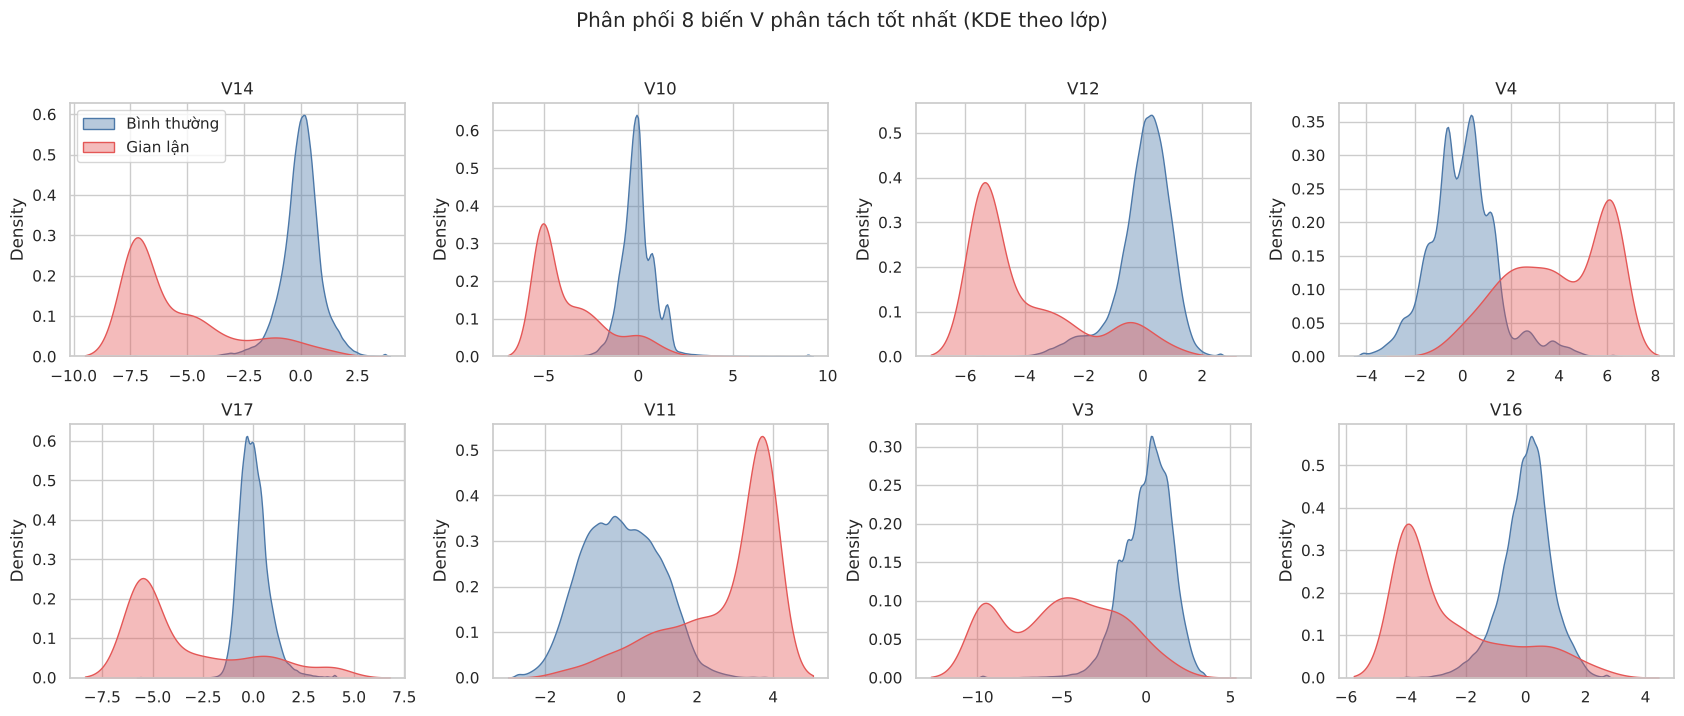

Biến dùng tạo tương tác trong fraud_pipeline.TOP_V: ('V14', 'V12', 'V10', 'V17')
Có nằm trong top-6 theo KS không? True


In [14]:
top8 = ks_df[ks_df["Biến"] != "Amount"].head(8)["Biến"].tolist()
fig, axes = plt.subplots(2, 4, figsize=(17, 7))
for ax, col in zip(axes.ravel(), top8):
    lo, hi = train[col].quantile([0.001, 0.999])
    sns.kdeplot(normal[col].clip(lo, hi), ax=ax, color=C_NORMAL, fill=True, alpha=0.4, label="Bình thường", common_norm=False)
    sns.kdeplot(fraud[col].clip(lo, hi), ax=ax, color=C_FRAUD, fill=True, alpha=0.4, label="Gian lận", common_norm=False)
    ax.set_title(col)
    ax.set_xlabel("")
axes[0, 0].legend()
plt.suptitle("Phân phối 8 biến V phân tách tốt nhất (KDE theo lớp)", y=1.02)
plt.tight_layout()
save_fig("05_top_v_kde")
plt.show()

print("Biến dùng tạo tương tác trong fraud_pipeline.TOP_V:", TOP_V)
print("Có nằm trong top-6 theo KS không?", all(v in ks_df[ks_df['Biến'] != 'Amount'].head(6)['Biến'].tolist() for v in TOP_V))

**Nhận xét.** Các biến `V14`, `V10`, `V12`, `V4`, `V17`, `V11`, `V3`, `V16`... có phân phối của hai lớp tách nhau rõ (KS từ 0,68 đến 0,85). Ở hầu hết các biến này giao dịch gian lận lệch về phía **âm sâu** (riêng `V4`, `V11`, `V2` lệch về phía dương) và có đuôi dài hơn nhiều. Bốn biến `V14`, `V10`, `V12`, `V17` nằm trong top 5 phân tách mạnh nhất (xác định **chỉ trên tập train**) và được chọn để tạo đặc trưng tương tác ở mục 6.

### 4.5 Tương quan
Tương quan Pearson trên toàn tập train bị lớp bình thường (99,8%) chi phối, nên so sánh thêm với tập **cân bằng** (toàn bộ ca gian lận + số ca bình thường được chọn ngẫu nhiên bằng nhau). Đây chỉ là công cụ khám phá, không dùng để huấn luyện.

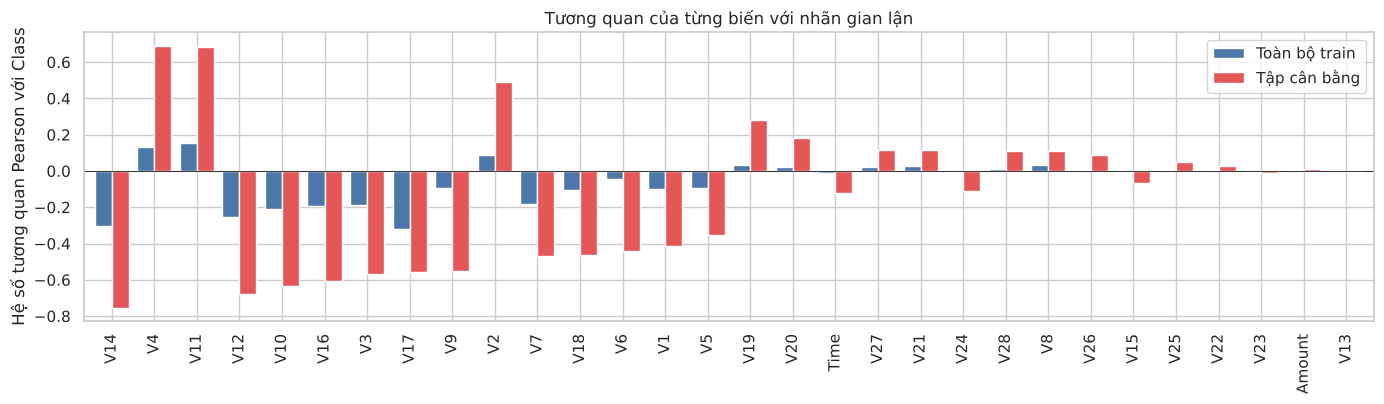

,Toàn bộ train,Tập cân bằng
V14,-0.3016,-0.7534
V4,0.1297,0.6915
V11,0.1521,0.6856
V12,-0.2547,-0.6800
V10,-0.2116,-0.6351
V16,-0.1903,-0.6058
V3,-0.1889,-0.5670
V17,-0.3207,-0.5590


In [15]:
num_cols = V_COLUMNS + ["Amount", "Time"]
corr_full = train[num_cols + ["Class"]].corr()["Class"].drop("Class")
bal = pd.concat([fraud, normal.sample(len(fraud), random_state=RANDOM_STATE)])
corr_bal = bal[num_cols + ["Class"]].corr()["Class"].drop("Class")

cmp = pd.DataFrame({"Toàn bộ train": corr_full, "Tập cân bằng": corr_bal})
cmp = cmp.reindex(corr_bal.abs().sort_values(ascending=False).index)
cmp.to_csv(TAB_DIR / "correlation_with_class.csv")

fig, ax = plt.subplots(figsize=(14, 4.2))
cmp.plot.bar(ax=ax, color=[C_NORMAL, C_FRAUD], width=0.8)
ax.axhline(0, color="k", lw=0.6)
ax.set(ylabel="Hệ số tương quan Pearson với Class", title="Tương quan của từng biến với nhãn gian lận")
plt.tight_layout()
save_fig("06_corr_with_class")
plt.show()
display(cmp.head(8))

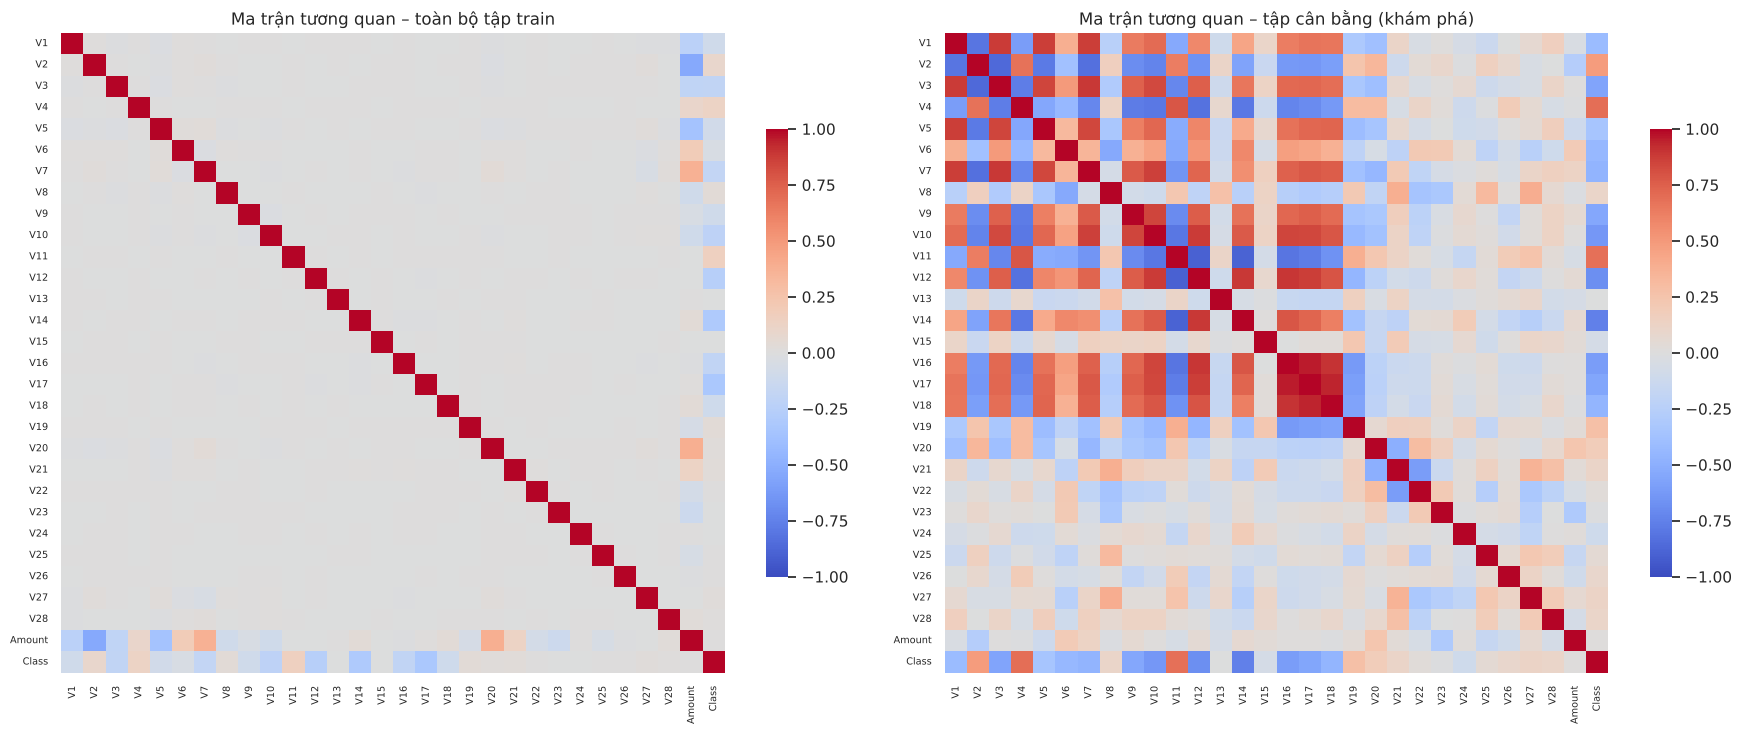

Tương quan tuyệt đối lớn nhất giữa các biến V: 0.042 (các thành phần PCA gần như trực giao)
Amount tương quan nhiều nhất với: {'V2': 0.539, 'V20': 0.388, 'V7': 0.372, 'V5': 0.361}


In [16]:
corr_matrix = train[V_COLUMNS + ["Amount", "Class"]].corr()
fig, axes = plt.subplots(1, 2, figsize=(18, 7.5), gridspec_kw={"width_ratios": [1, 1]})
sns.heatmap(corr_matrix, cmap="coolwarm", center=0, vmin=-1, vmax=1, ax=axes[0],
            cbar_kws={"shrink": 0.7}, xticklabels=True, yticklabels=True)
axes[0].set_title("Ma trận tương quan – toàn bộ tập train")
corr_bal_m = bal[V_COLUMNS + ["Amount", "Class"]].corr()
sns.heatmap(corr_bal_m, cmap="coolwarm", center=0, vmin=-1, vmax=1, ax=axes[1],
            cbar_kws={"shrink": 0.7}, xticklabels=True, yticklabels=True)
axes[1].set_title("Ma trận tương quan – tập cân bằng (khám phá)")
for ax in axes:
    ax.tick_params(labelsize=7)
plt.tight_layout()
save_fig("07_correlation_heatmaps")
plt.show()

vv = train[V_COLUMNS].corr().abs().to_numpy(copy=True)
np.fill_diagonal(vv, 0)
print(f"Tương quan tuyệt đối lớn nhất giữa các biến V: {vv.max():.3f} (các thành phần PCA gần như trực giao)")
amt_corr = train[V_COLUMNS].corrwith(train.Amount).abs().sort_values(ascending=False).head(4)
print("Amount tương quan nhiều nhất với:", {k: round(v, 3) for k, v in amt_corr.items()})

**Nhận xét.**
* Trên tập cân bằng, tương quan với nhãn của `V14` (-0,75), `V4` (+0,69), `V11` (+0,69), `V12`, `V10`, `V16`... lộ rõ hơn hẳn so với trên toàn bộ train (nơi cao nhất chỉ khoảng 0,32 ở `V17`), vì lớp bình thường chiếm 99,8% làm loãng tương quan.
* Các biến `V` gần như **không tương quan với nhau** (|r| tối đa rất nhỏ) vì là thành phần PCA, nên không có đa cộng tuyến đáng lo ở nhóm V. Không cần loại biến theo tiêu chí tương quan.
* `Amount` tương quan vừa phải với một số biến V (`V2`: 0,54; `V20`, `V7`, `V5`: khoảng 0,36-0,39), nghĩa là `Amount` mang thông tin chồng một phần với V.

### 4.6 Giá trị thiếu
Không có giá trị thiếu (mục 2). Chiến lược: vẫn đưa `SimpleImputer` (median cho số, most_frequent cho nhị phân/phân loại) vào `ColumnTransformer`; imputer này chỉ được fit trên train/fold train.

## 5. Xử lý ngoại lai (Outliers)

Trong bài toán gian lận, **ngoại lai thường chính là tín hiệu**. Trước khi quyết định, ta đo tỷ lệ ngoại lai (theo quy tắc IQR 1,5 tính trên train) của từng lớp.

In [17]:
def iqr_outlier_mask(frame: pd.DataFrame, cols: list[str]) -> pd.DataFrame:
    """Trả về mask True nếu giá trị nằm ngoài [Q1 - 1.5 IQR, Q3 + 1.5 IQR] (tính trên train)."""
    q1, q3 = train[cols].quantile(0.25), train[cols].quantile(0.75)
    iqr = q3 - q1
    return (frame[cols] < q1 - 1.5 * iqr) | (frame[cols] > q3 + 1.5 * iqr)

cols = V_COLUMNS + ["Amount"]
out_fraud, out_normal = iqr_outlier_mask(fraud, cols), iqr_outlier_mask(normal, cols)
rate = pd.DataFrame({
    "% ngoại lai - bình thường": 100 * out_normal.mean(),
    "% ngoại lai - gian lận": 100 * out_fraud.mean(),
})
rate["Tỷ số"] = rate.iloc[:, 1] / rate.iloc[:, 0]
rate = rate.sort_values("% ngoại lai - gian lận", ascending=False)
rate.to_csv(TAB_DIR / "outlier_rate_by_class.csv")
display(rate.head(8))

any_out_fraud = out_fraud.any(axis=1).mean()
any_out_normal = out_normal.any(axis=1).mean()
print(f"Giao dịch có ÍT NHẤT một ngoại lai: gian lận {any_out_fraud:.1%} vs bình thường {any_out_normal:.1%}")
print(f"Nếu loại mọi dòng có ngoại lai, ta mất {out_fraud.any(axis=1).sum()} / {len(fraud)} giao dịch gian lận.")

,% ngoại lai - bình thường,% ngoại lai - gian lận,Tỷ số
V14,4.7881,87.8307,18.3434
V12,5.2325,83.5979,15.9766
V10,3.1262,82.0106,26.2334
V17,2.4867,81.7460,32.8728
V16,2.7789,71.9577,25.8945
V27,13.6133,70.3704,5.1692
V4,3.8437,63.2275,16.4495
V3,1.0600,62.9630,59.3986


Giao dịch có ÍT NHẤT một ngoại lai: gian lận 97.1% vs bình thường 48.5%
Nếu loại mọi dòng có ngoại lai, ta mất 367 / 378 giao dịch gian lận.


**Nhận xét.** Ở các biến phân tách mạnh (`V14`, `V12`, `V10`, `V17`), tỷ lệ ngoại lai của giao dịch gian lận (khoảng 82-88%) cao gấp 16-33 lần giao dịch bình thường (2-5%). Có tới 97,1% giao dịch gian lận chứa ít nhất một ngoại lai, nên loại mọi dòng có ngoại lai sẽ **xóa 367/378 ca gian lận**, tức xóa đúng thứ cần học. (Ghi chú: do có tới 29 biến, quy tắc IQR cũng đánh dấu khoảng 48,5% giao dịch bình thường là có ít nhất một ngoại lai, nên quy tắc này vốn quá nhạy với dữ liệu nhiều chiều.) Vì vậy **không xóa dòng ngoại lai**.

Tuy nhiên vẫn có hai cách "xử lý mềm" để mô hình tuyến tính/khoảng cách không bị đuôi cực lớn làm méo: (a) `RobustScaler` + `log1p` cho `Amount`; (b) winsorize (cắt đuôi theo phân vị, **fit trên train fold**). Thí nghiệm sau kiểm chứng bằng 5-fold CV trên train (PR-AUC) xem cách nào tốt hơn. Winsorizer nằm *trong* Pipeline nên phân vị chỉ học từ fold train.

In [18]:
class Winsorizer(BaseEstimator, TransformerMixin):
    """Cắt giá trị về [phân vị dưới, phân vị trên] học từ dữ liệu fit."""

    def __init__(self, lower=0.01, upper=0.99, columns=None):
        self.lower, self.upper, self.columns = lower, upper, columns

    def fit(self, X, y=None):
        cols = self.columns or list(X.columns)
        self.cols_ = cols
        self.low_ = X[cols].quantile(self.lower)
        self.high_ = X[cols].quantile(self.upper)
        return self

    def transform(self, X):
        out = X.copy()
        out[self.cols_] = X[self.cols_].clip(self.low_, self.high_, axis=1)
        return out


from imblearn.pipeline import Pipeline as ImbPipeline

cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
spw = float((y_train == 0).sum() / (y_train == 1).sum())
wins_cols = V_COLUMNS + ["Amount"]
variants = {
    "Không cắt đuôi (RobustScaler cho Amount)": None,
    "Winsorize 1% - 99%": Winsorizer(0.01, 0.99, wins_cols),
    "Winsorize 0.1% - 99.9%": Winsorizer(0.001, 0.999, wins_cols),
}
models = {
    "Logistic Regression": lambda: LogisticRegression(class_weight="balanced", max_iter=2000),
    "XGBoost": lambda: XGBClassifier(n_estimators=200, max_depth=4, learning_rate=0.1, scale_pos_weight=spw,
                                      tree_method="hist", n_jobs=2, random_state=RANDOM_STATE),
}
rows = []
for vname, wins in variants.items():
    for mname, mk in models.items():
        base = build_pipeline(mk())
        pipe = base if wins is None else ImbPipeline([("wins", wins), *base.steps])
        s = cross_val_score(pipe, X_train, y_train, cv=cv5, scoring="average_precision", n_jobs=1)
        rows.append((vname, mname, s.mean(), s.std()))
outlier_exp = pd.DataFrame(rows, columns=["Cách xử lý ngoại lai", "Mô hình", "PR-AUC (CV trung bình)", "Độ lệch chuẩn"])
outlier_exp.to_csv(TAB_DIR / "outlier_experiment.csv", index=False)
outlier_exp

,Cách xử lý ngoại lai,Mô hình,PR-AUC (CV trung bình),Độ lệch chuẩn
0,Không cắt đuôi (RobustScaler cho Amount),Logistic Regression,0.7863,0.0380
1,Không cắt đuôi (RobustScaler cho Amount),XGBoost,0.8344,0.0302
2,Winsorize 1% - 99%,Logistic Regression,0.7451,0.0553
3,Winsorize 1% - 99%,XGBoost,0.8394,0.0309
4,Winsorize 0.1% - 99.9%,Logistic Regression,0.7754,0.0447
5,Winsorize 0.1% - 99.9%,XGBoost,0.8377,0.0313


**Kết luận mục 5.** Với Logistic Regression, cắt đuôi **làm giảm** PR-AUC (0,786 xuống 0,745 khi cắt 1%-99% và 0,775 khi cắt 0,1%-99,9%). Với XGBoost, chênh lệch chỉ khoảng +0,003 đến +0,005, **nhỏ hơn nhiều so với độ lệch chuẩn giữa các fold (≈ 0,03)** nên không có ý nghĩa thống kê. Cắt đuôi vì vậy không mang lại lợi ích rõ ràng nhưng lại làm mất thông tin cực trị của gian lận. Pipeline cuối cùng **giữ nguyên ngoại lai**, chỉ dùng `RobustScaler` + `log1p` cho `Amount`.

## 6. Kỹ nghệ đặc trưng (Feature Engineering)

Các đặc trưng mới được cài trong lớp `FraudFeatureEngineer` (file `fraud_pipeline.py`) dưới dạng transformer của scikit-learn. Lớp này **không học tham số từ dữ liệu** nên không gây rò rỉ khi dùng trong cross-validation.

| Đặc trưng | Công thức | Lý do |
|---|---|---|
| `Amount_log` | `log1p(Amount)` | Giảm lệch phải của số tiền |
| `Amount_small` | `Amount < 1` | Gian lận có tỷ lệ giao dịch số tiền rất nhỏ cao gấp ~2 lần (mục 4.2) |
| `Hour` | `(Time mod 86400) / 3600` | Quy đổi giây sang giờ trong ngày |
| `Hour_sin`, `Hour_cos` | sin, cos của `2πHour/24` | Giờ có tính chu kỳ (23h gần 0h) |
| `Period` | night/morning/afternoon/evening | Biến phân loại (mã hóa one-hot); đêm có tỷ lệ gian lận cao (mục 4.3) |
| `V_norm` | `‖V1..V28‖₂` | Đo mức bất thường tổng thể so với tâm PCA |
| `V14_x_V12`, `V14_x_V10`, `V14_x_V17`, `V12_x_V10` | tích hai biến | Kết hợp các biến V phân tách mạnh nhất |

`Time` thô bị loại khỏi tập đặc trưng.

In [19]:
fe = FraudFeatureEngineer().fit(X_train)
train_fe = fe.transform(X_train)
print("Số cột đầu vào:", X_train.shape[1], "-> số cột sau kỹ nghệ đặc trưng:", train_fe.shape[1])
new_cols = [c for c in train_fe.columns if c not in V_COLUMNS + ["Amount"]]
print("Các đặc trưng mới:", new_cols)
train_fe[new_cols].head()

Số cột đầu vào: 30 -> số cột sau kỹ nghệ đặc trưng: 40
Các đặc trưng mới: ['Amount_log', 'Amount_small', 'Hour', 'Hour_sin', 'Hour_cos', 'Period', 'V_norm', 'V14_x_V12', 'V14_x_V10', 'V14_x_V17', 'V12_x_V10']


,Amount_log,Amount_small,Hour,Hour_sin,Hour_cos,Period,V_norm,V14_x_V12,V14_x_V10,V14_x_V17,V12_x_V10
225399,3.4965,0.0000,16.1525,-0.8853,-0.4650,afternoon,6.5710,0.2212,-0.4915,-0.1196,-1.1063
133746,2.0782,0.0000,22.4211,-0.4017,0.9158,evening,4.2706,1.5203,-0.4163,-0.2289,-0.8506
185792,2.7695,0.0000,11.3100,0.1797,-0.9837,morning,4.5916,-0.7165,0.3432,-0.5470,-0.5173
148925,2.9069,0.0000,1.3728,0.3517,0.9361,night,6.6364,-2.2004,1.4215,-0.5890,-2.0355
18398,3.2189,0.0000,8.2006,0.8386,-0.5448,morning,4.6494,-0.0006,-0.0666,-0.0352,0.0215


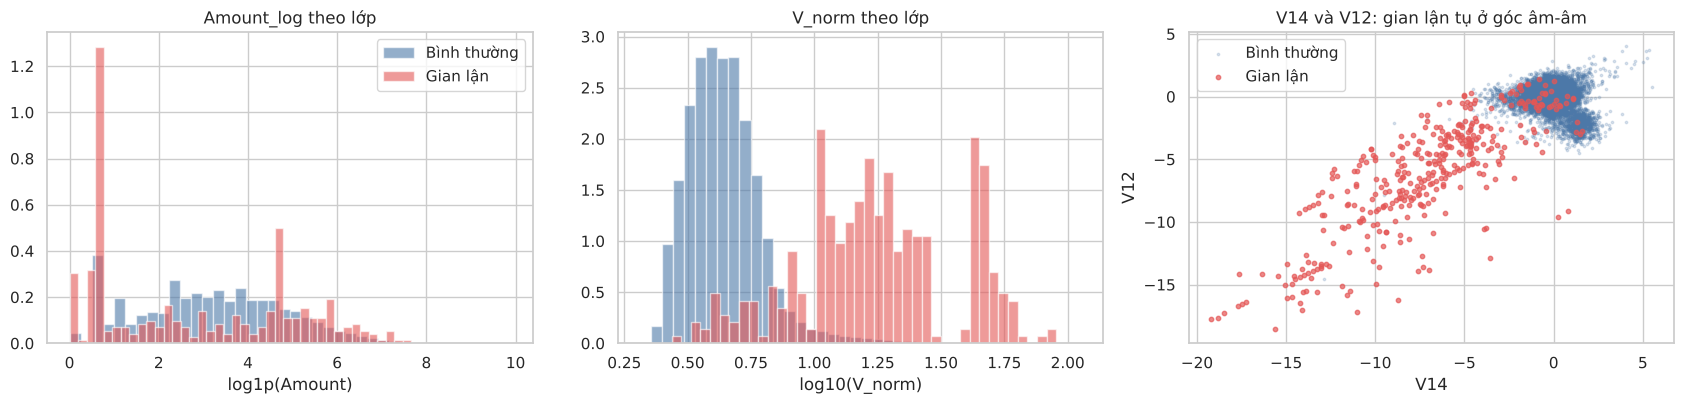

,Tương quan với Class
V14_x_V12,0.5850
V12_x_V10,0.5458
V14_x_V17,0.5428
V14_x_V10,0.5248
V_norm,0.2608
Hour,-0.0156
Hour_sin,0.0130
Amount_small,0.0118
Amount_log,-0.0082
Hour_cos,0.0036


In [20]:
fe_df = train_fe.assign(Class=y_train.values)
num_new = [c for c in new_cols if c != "Period"]
corr_new = fe_df[num_new + ["Class"]].corr()["Class"].drop("Class")
cmp_fe = corr_new.rename("Tương quan với Class").sort_values(key=abs, ascending=False)
cmp_fe.to_csv(TAB_DIR / "engineered_feature_corr.csv")

fig, axes = plt.subplots(1, 3, figsize=(17, 4.2))
# (a) Amount_log
for c, name, col in [(0, "Bình thường", C_NORMAL), (1, "Gian lận", C_FRAUD)]:
    axes[0].hist(fe_df.loc[fe_df.Class == c, "Amount_log"], bins=40, density=True, alpha=0.6, color=col, label=name)
axes[0].set(title="Amount_log theo lớp", xlabel="log1p(Amount)")
axes[0].legend()
# (b) V_norm (thang log)
for c, name, col in [(0, "Bình thường", C_NORMAL), (1, "Gian lận", C_FRAUD)]:
    axes[1].hist(np.log10(fe_df.loc[fe_df.Class == c, "V_norm"]), bins=40, density=True, alpha=0.6, color=col, label=name)
axes[1].set(title="V_norm theo lớp", xlabel="log10(V_norm)")
# (c) tương tác mạnh nhất
sample = fe_df.sample(15000, random_state=RANDOM_STATE)
sample = pd.concat([sample[sample.Class == 0], fe_df[fe_df.Class == 1]])
axes[2].scatter(sample.loc[sample.Class == 0, "V14"], sample.loc[sample.Class == 0, "V12"], s=3, alpha=0.2, color=C_NORMAL, label="Bình thường")
axes[2].scatter(sample.loc[sample.Class == 1, "V14"], sample.loc[sample.Class == 1, "V12"], s=10, alpha=0.7, color=C_FRAUD, label="Gian lận")
axes[2].set(title="V14 và V12: gian lận tụ ở góc âm-âm", xlabel="V14", ylabel="V12")
axes[2].legend()
plt.tight_layout()
save_fig("08_engineered_features")
plt.show()

display(cmp_fe.to_frame())

**Nhận xét.** Các tích `V14_x_V12`, `V12_x_V10`, `V14_x_V17`, `V14_x_V10` có tương quan với nhãn (≈ 0,5-0,6) **cao hơn nhiều so với từng biến V đơn lẻ** (≤ 0,32), vì gian lận thường đồng thời có các giá trị âm lớn ở nhiều biến này. `V_norm` của giao dịch gian lận cũng lớn hơn rõ rệt (trung bình khoảng 22 so với 4,7). Các đặc trưng thời gian (`Hour`, `Hour_sin`, `Hour_cos`) và số tiền có tương quan tuyến tính với nhãn rất thấp (|r| < 0,02), vì tác động của chúng là phi tuyến (ví dụ khung giờ đêm), nên hệ số tương quan tuyến tính không phản ánh hết giá trị của chúng. Mức đóng góp thực tế của kỹ nghệ đặc trưng sẽ được đo bằng **thí nghiệm ablation** (có/không có kỹ nghệ đặc trưng) trong notebook 02.

## 7. Thiết kế `ColumnTransformer` và kiểm chứng không rò rỉ

Luồng dữ liệu của toàn bộ Pipeline (xây bằng `build_pipeline` trong `fraud_pipeline.py`):

```
X thô (Time, V1..V28, Amount)
   │
   ▼  FraudFeatureEngineer      (không học tham số)
   │
   ▼  ColumnTransformer
   │     ├─ nhóm V + tương tác ──► SimpleImputer(median) ► StandardScaler
   │     ├─ Amount, Hour...      ──► SimpleImputer(median) ► RobustScaler
   │     ├─ Amount_small (cờ)    ──► SimpleImputer(most_frequent)
   │     └─ Period (phân loại)   ──► SimpleImputer(most_frequent) ► OneHotEncoder(handle_unknown='ignore')
   │
   ▼  [Sampler: SMOTE / RandomUnderSampler]   (chỉ áp dụng khi fit)
   │
   ▼  Mô hình (LR / k-NN / DT / RF / XGBoost)
```

In [21]:
from sklearn import set_config
set_config(display="diagram")
demo_pipe = build_pipeline(LogisticRegression(class_weight="balanced", max_iter=2000))
demo_pipe

,steps,"[('fe', ...), ('prep', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('v', ...), ('amt_time', ...), ...]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e.g. ``""{feature_name}__{transformer_name}""``. See :meth:`str.format` method from the standard library for more info... versionadded:: 1.0.. versionchanged:: 1.6 `verbose_feature_names_out` can be a callable or a string to be formatted.",False
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_we

In [22]:
# Kiểm chứng: fit CHỈ trên train, rồi transform cả train và test.
fe_ = FraudFeatureEngineer().fit(X_train)
prep = build_preprocessor()
Xtr_t = prep.fit_transform(fe_.transform(X_train))
Xte_t = prep.transform(fe_.transform(X_test))
feature_names = list(prep.get_feature_names_out())
print("Ma trận đặc trưng sau tiền xử lý:", Xtr_t.shape, "(train),", Xte_t.shape, "(test)")
print("Tên các đặc trưng cuối:", feature_names[-8:], "...")

tr_df = pd.DataFrame(Xtr_t, columns=feature_names)
te_df = pd.DataFrame(Xte_t, columns=feature_names)
check = pd.DataFrame({
    "Trung bình (train)": tr_df[["V1", "V14", "Amount"]].mean(),
    "Độ lệch chuẩn (train)": tr_df[["V1", "V14", "Amount"]].std(),
    "Trung bình (test)": te_df[["V1", "V14", "Amount"]].mean(),
    "Độ lệch chuẩn (test)": te_df[["V1", "V14", "Amount"]].std(),
})
display(check)

Ma trận đặc trưng sau tiền xử lý: (226980, 43) (train), (56746, 43) (test)
Tên các đặc trưng cuối: ['Hour', 'Hour_sin', 'Hour_cos', 'Amount_small', 'Period_afternoon', 'Period_evening', 'Period_morning', 'Period_night'] ...


,Trung bình (train),Độ lệch chuẩn (train),Trung bình (test),Độ lệch chuẩn (test)
V1,0.0000,1.0000,0.0023,1.0019
V14,-0.0000,1.0000,0.0099,0.9891
Amount,0.9189,3.4059,0.9248,3.7158


In [23]:
# Bằng chứng không rò rỉ: tham số của scaler phải bằng thống kê của TRAIN, khác thống kê của TOÀN BỘ dữ liệu.
v_scaler = prep.named_transformers_["v"].named_steps["sc"]
idx = V_COLUMNS.index("V14")
mean_train = fe_.transform(X_train)["V14"].mean()
mean_all = pd.concat([fe_.transform(X_train), fe_.transform(X_test)])["V14"].mean()
print(f"mean_ học bởi scaler cho V14 : {v_scaler.mean_[idx]:.8f}")
print(f"trung bình V14 trên train    : {mean_train:.8f}")
print(f"trung bình V14 trên train+test: {mean_all:.8f}")
assert np.isclose(v_scaler.mean_[idx], mean_train), "Scaler phải fit chỉ trên train!"
assert not np.isclose(v_scaler.mean_[idx], mean_all, atol=1e-12), "Scaler không được thấy dữ liệu test!"
print("OK: scaler chỉ học từ tập train.")

mean_ học bởi scaler cho V14 : -0.00162946
trung bình V14 trên train    : -0.00162946
trung bình V14 trên train+test: 0.00025232
OK: scaler chỉ học từ tập train.


Trung bình/độ lệch chuẩn của train sau chuẩn hóa là (0, 1) đúng như kỳ vọng, còn trên test chỉ **xấp xỉ** (0, 1): test được biến đổi bằng tham số của train. Đây là hành vi đúng; nếu test cũng có trung bình đúng bằng 0 tuyệt đối thì đó là dấu hiệu scaler đã được fit trên test.

Từ notebook 02, mọi bước (kỹ nghệ đặc trưng, imputer, scaler, encoder, sampler) đều nằm trong một `Pipeline`, nên `cross_val_score`, `GridSearchCV`, `RandomizedSearchCV` tự động fit lại các bước này trên từng fold train.

## 8. Mức độ quan trọng đặc trưng (phân tích đơn biến)

Đây là phân tích sơ bộ, **chỉ dùng train**, trên các đặc trưng sau tiền xử lý. Dùng hai thước đo:
* **ANOVA F-score**: mức tách biệt trung bình giữa hai lớp (đánh giá tuyến tính).
* **Average Precision đơn biến**: dùng chính đặc trưng làm "điểm số" dự đoán gian lận rồi tính PR-AUC (lấy giá trị tốt hơn giữa dấu `+` và `-`). Thước đo này phù hợp với dữ liệu mất cân bằng và không giả định dạng quan hệ tuyến tính.

Phân tích dựa trên mô hình (permutation importance, SHAP) thực hiện ở notebook 02.

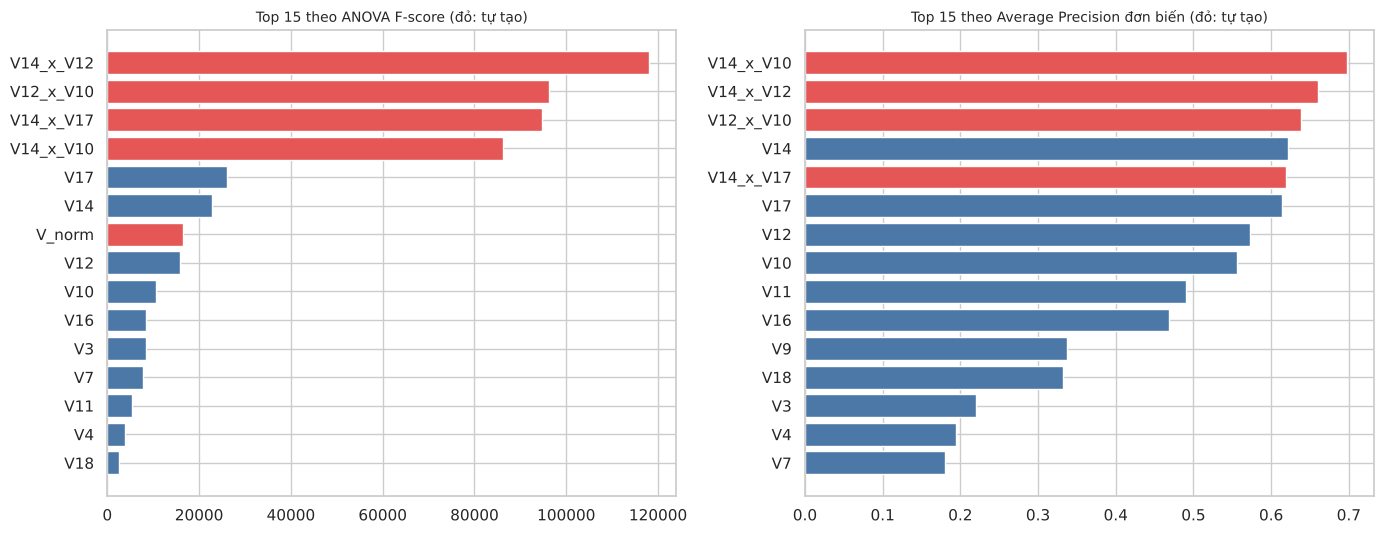

,Đặc trưng,ANOVA F,AP đơn biến
0,V14_x_V10,"86,291.8811",0.6975
1,V14_x_V12,"118,077.9477",0.6601
2,V12_x_V10,"96,312.9169",0.6384
3,V14,"22,719.8473",0.6214
4,V14_x_V17,"94,790.4371",0.6189
5,V17,"26,015.0464",0.6138
6,V12,"15,743.9266",0.5726
7,V10,"10,643.5541",0.5555
8,V11,"5,376.4537",0.4903
9,V16,"8,530.7995",0.4687


In [24]:
f_scores, _ = f_classif(Xtr_t, y_train)
y_arr = y_train.to_numpy()
ap_uni = [max(average_precision_score(y_arr, Xtr_t[:, j]), average_precision_score(y_arr, -Xtr_t[:, j]))
          for j in range(Xtr_t.shape[1])]
imp = pd.DataFrame({"Đặc trưng": feature_names, "ANOVA F": f_scores, "AP đơn biến": ap_uni})
imp = imp.sort_values("AP đơn biến", ascending=False).reset_index(drop=True)
imp.to_csv(TAB_DIR / "univariate_importance.csv", index=False)

engineered = set(new_cols) | {c for c in feature_names if c.startswith("Period_")}
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for ax, key, title in [(axes[0], "ANOVA F", "ANOVA F-score"), (axes[1], "AP đơn biến", "Average Precision đơn biến")]:
    t = imp.sort_values(key, ascending=False).head(15).iloc[::-1]
    ax.barh(t["Đặc trưng"], t[key], color=[C_FRAUD if f in engineered else C_NORMAL for f in t["Đặc trưng"]])
    ax.set_title(f"Top 15 theo {title} (đỏ: tự tạo)", fontsize=10)
plt.tight_layout()
save_fig("09_univariate_importance")
plt.show()
imp.head(10)

**Nhận xét.** Trong top đầu của cả hai thước đo đều xuất hiện các đặc trưng tự tạo (tương tác `V14_x_V12`, `V12_x_V10`..., `V_norm`) xen kẽ với `V14`, `V17`, `V12`, `V10`, cho thấy kỹ nghệ đặc trưng đã bổ sung thông tin hữu ích ở mức đơn biến. Hiệu quả thực sự khi kết hợp với mô hình được kiểm tra bằng ablation ở notebook 02.

## 9. Tổng kết chiến lược tiền xử lý

| Vấn đề | Quyết định | Lý do |
|---|---|---|
| Dòng trùng lặp | Loại 1.081 dòng **trước khi chia** | Tránh cùng giao dịch ở cả train và test |
| Giá trị thiếu | Không có; vẫn có `SimpleImputer` trong pipeline | Chống lỗi với dữ liệu mới; chỉ fit trên train |
| Ngoại lai | **Không xóa**; `RobustScaler` + `log1p` cho `Amount` | Gian lận chính là ngoại lai; thí nghiệm winsorize không cải thiện |
| Chuẩn hóa | `StandardScaler` cho V, `RobustScaler` cho Amount/Hour | Phù hợp phân phối từng nhóm; cần cho LR và k-NN |
| Mã hóa | `OneHotEncoder` cho `Period` | Biến phân loại tự tạo từ thời gian |
| Kỹ nghệ đặc trưng | 12 đặc trưng mới, bỏ `Time` thô | Dựa trên EDA của train (mục 4, 6) |
| Mất cân bằng | Xử lý trong Pipeline (notebook 02) | Tránh rò rỉ do SMOTE |
| Chia dữ liệu | Stratified 80/20, `random_state=42`, trước EDA | Giữ tập test độc lập |

Notebook tiếp theo (`02_Modeling_Evaluation.ipynb`) dùng đúng các thành phần này để huấn luyện, so sánh và tinh chỉnh các mô hình.